In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Load Cleaned Dataset
df=pd.read_csv("cleaned_new_df.csv")
df['Year']=df['Year'].astype(int)
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16286,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16287,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16288,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16289,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [2]:
# Column Analysis
print(df.info())
print('-'*100)
print(df.describe())


<class 'pandas.DataFrame'>
RangeIndex: 16291 entries, 0 to 16290
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  str    
 2   Platform      16291 non-null  str    
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  str    
 5   Publisher     16291 non-null  str    
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), str(4)
memory usage: 1.4 MB
None
----------------------------------------------------------------------------------------------------
               Rank          Year      NA_Sales      EU_Sales      JP_Sales  \
count  16291.000000  16291.000000  16291.000000  16291.000000  16291.000000   
mean    8290.190228  

In [3]:
#remove unnecessary columns
df = df.drop(['Rank', 'Name', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales'], axis=1)

In [4]:
# Create Sales_Category
#here we are going to Sales Category for classification target
'''
Flop → below median (low sales).

Average → between median and 75th percentile.

Hit → above 75th percentile.

'''
q25 = df['Global_Sales'].quantile(0.25)   # 25% = 0.06
q50 = df['Global_Sales'].quantile(0.50)   # 50% = 0.17 (median)but
q75 = df['Global_Sales'].quantile(0.75)   # 75% = 0.48
def category_decide(x):
    if x>=q75:
        return 'Hit'
    elif x>=q50:
        return "Average"
    else:
        return "Flop"
        
df['Sales_Category']=df['Global_Sales'].apply(category_decide)
df


,Platform,Year,Genre,Publisher,Global_Sales,Sales_Category
0,Wii,2006,Sports,Nintendo,82.74,Hit
1,NES,1985,Platform,Nintendo,40.24,Hit
2,Wii,2008,Racing,Nintendo,35.82,Hit
3,Wii,2009,Sports,Nintendo,33.00,Hit
4,GB,1996,Role-Playing,Nintendo,31.37,Hit
...,...,...,...,...,...,...
16286,GBA,2002,Platform,Kemco,0.01,Flop
16287,GC,2003,Shooter,Infogrames,0.01,Flop
16288,PS2,2008,Racing,Activision,0.01,Flop
16289,DS,2010,Puzzle,7G//AMES,0.01,Flop


In [5]:
# check class balance
class_balance=df['Sales_Category'].value_counts()
class_balance

Sales_Category
Flop       7982
Average    4222
Hit        4087
Name: count, dtype: int64

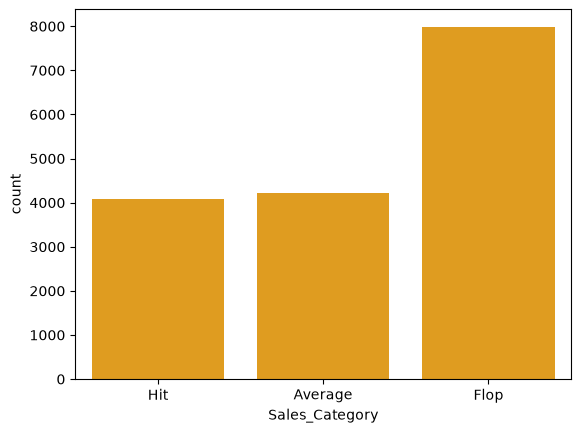

In [6]:
#lets see through plots how many are get Hit,Average,Flop
sns.countplot(x=df['Sales_Category'],color='Orange')
plt.show()

In [7]:
df.to_csv("feature_engineered_dataset.csv", index=False)
